# Case PharmaSaude

## Context and Problem

PharmaSaude has been operating in the pharmaceutical, veterinary, and wellness sectors for over 10 years, with physical units distributed across Northeast Brazil and, more recently, with online sales nationwide.

The pharmaceutical market has shown great resilience and continues to expand. Many people changed their consumption habits during the isolation period, starting to prioritize self-care, prevention, and health maintenance more rigorously. PharmaSaude's CEO has a major concern regarding how the company will capture and retain this growing market share.

Since the beginning of last year, PharmaSaude initiated a plan to accelerate the company's digital transformation and structure customer data to improve their buying journey. Based on the analyses conducted, they decided to launch a loyalty program that allows identifying customer purchases in physical stores, the channel where they have the highest sales volume and direct interaction.

The CEO is analytical and results-oriented, actively participates in the company's transformations, and guides the team in strategic planning. He provides an environment with total autonomy for the team to make the necessary changes and reviews the results of the initiatives monthly in a committee. The expectations regarding the return on these transformations are high.

The CEO sent me some strategic questions, asking for my help to answer them:

## Strategic Questions

1. Demand Forecasting: We want to plan the sales of Adult medications for the next six months. What is the daily sales forecast for this category across our units?
2. Customer Segmentation: We know that not all customers have the same profile; some generate a much higher LTV (Lifetime Value) than others. Can we segregate customers into specific groups? Is there any significantly more profitable segment?
3. Churn and Retention Analysis: One of the priorities for next year is to increase retention. In the company, we consider a customer inactive when they do not make any transactions for more than 90 days. What would be the target group for retention actions? That is: which customer profile presents the highest risk of churn?
4. Product Recommendation: Based on purchase history and browsing behavior, what other products (such as vitamins, dermocosmetics, or hygiene items) can we offer in a personalized way to each customer?
---


# Data Reading

In [3]:
import sys
sys.path.append("..")

In [4]:
import numpy as np
import pandas as pd
import datetime as  dt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from pathlib import Path

In [5]:
from src.data import load_data

In [6]:
path = "../data/raw/"
output_dir = Path("../charts_and_figures")
output_dir.mkdir(exist_ok=True)
sns.set_style("darkgrid")

In [7]:
from src.data import load_raw_tables    

customers_df, products_df, sales_df = load_raw_tables(str(path))

In [8]:
# Customer table
customers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105924 entries, 0 to 105923
Data columns (total 4 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   CUSTOMER_ID          105924 non-null  int64 
 1   SEX                  105924 non-null  object
 2   BIRTH_DATE           105924 non-null  object
 3   FIRST_PURCHASE_DATE  105924 non-null  object
dtypes: int64(1), object(3)
memory usage: 3.2+ MB


In [9]:
# Product table
products_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38303 entries, 0 to 38302
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   PRODUCT_ID  38303 non-null  int64 
 1   UNIT        38303 non-null  object
 2   LEVEL_1     25734 non-null  object
 3   LEVEL_2     25734 non-null  object
 4   LEVEL_3     25473 non-null  object
 5   LEVEL_4     23190 non-null  object
dtypes: int64(1), object(5)
memory usage: 1.8+ MB


In [10]:
# Sales table
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1859583 entries, 0 to 1859582
Data columns (total 7 columns):
 #   Column         Dtype  
---  ------         -----  
 0   SALE_ID        int64  
 1   SALE_DATE      object 
 2   CUSTOMER_ID    float64
 3   PRODUCT_ID     int64  
 4   QUANTITY       float64
 5   SALE_CATEGORY  object 
 6   BRANCH         int64  
dtypes: float64(2), int64(3), object(2)
memory usage: 99.3+ MB


In [11]:
from src.data import clean_tables

clean_tables(customers_df, products_df, sales_df)

(        CUSTOMER_ID  SEX BIRTH_DATE FIRST_PURCHASE_DATE
 0                 0  NaN 1900-01-01          2017-03-06
 1                 1  NaN 1900-01-01          2017-03-06
 2                 2  NaN 1900-01-01          2017-03-06
 3                 3  NaN 1900-01-01          2017-02-18
 4                 4  NaN 1900-01-01          2017-01-16
 ...             ...  ...        ...                 ...
 105919       105919    F 1977-09-11          2021-10-16
 105920       105920  NaN 1900-01-01          1900-01-01
 105921       105921  NaN 1900-01-01          1900-01-01
 105922       105922    F 1985-05-15          2021-10-16
 105923       105923    F 1986-09-23          2021-10-16
 
 [105924 rows x 4 columns],
        PRODUCT_ID UNIT LEVEL_1                  LEVEL_2  \
 0               0   UN   ADULT  NUTRITION AND DIETETICS   
 1               2   UN   ADULT  NUTRITION AND DIETETICS   
 2               3   UN     NaN                      NaN   
 3               4   UN   ADULT               

In [12]:
# Retirar espaço vazio nas strings dos niveis
from src.data import _first_word

products_df["LEVEL_1"] = products_df["LEVEL_1"].apply(_first_word)



In [13]:
products_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38303 entries, 0 to 38302
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   PRODUCT_ID  38303 non-null  int64 
 1   UNIT        38303 non-null  object
 2   LEVEL_1     25734 non-null  object
 3   LEVEL_2     25734 non-null  object
 4   LEVEL_3     25473 non-null  object
 5   LEVEL_4     23190 non-null  object
dtypes: int64(1), object(5)
memory usage: 1.8+ MB


In [14]:
# Distribuição percentual de cada nivel 2 nos niveis 1
n1_n2 = (products_df.groupby("LEVEL_1")['LEVEL_2'].value_counts()/products_df.groupby("LEVEL_1")['LEVEL_2'].count()).reset_index(0)

# 'LEVEL_2' is currently the index, not a column. Reset index to convert it to a column.
n1_n2.reset_index(inplace=True)

# The percentage values are in the column named '0'. Rename it to 'value'.
n1_n2.rename(columns={0: 'value'}, inplace=True)

# Round the values as intended.
n1_n2['value'] = n1_n2['value'].round(3)

fig = px.bar(n1_n2, x = 'LEVEL_1', y = 'value', color='LEVEL_2',labels={"value":"Percentage (%)"},template="seaborn")
fig.update_layout(title={'text':'Product composition based on Main Category','x':0.25})
output_file = output_dir / "product_composition.png"
fig.write_image(output_file)
fig.show()

Insights:
- PharmaSaude has good amount of its sales, based on the sample, of nutirion and dietetics products for all the expected segments (elderly, baby and pregnant). The sample has not shown any signals of medication sold at PharmaSaude, which is unusual for a pharma. 

---
# 1. Demand Forecast

In [15]:
total_sales= sales_df[['SALE_DATE','QUANTITY']].groupby('SALE_DATE').sum()
total_sales.index = pd.to_datetime(total_sales.index)

In [16]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=total_sales.index, y=total_sales['QUANTITY'],
                  mode='lines',
                  name='Real'))
fig.update_layout(title={'text':'Total Sales Over Time','x':0.25})

fig.show()
fig.write_image(output_dir / "total_sales_over_time.png")

Insights:
- Indices of sazonal cycles - it looks like PharmaSaude has sazonal peaks every 2 weeks. As this is a sample of the data, would be reasonable to investigate. 
- Data of a shor period - around one year of data. 
- There is a peak of sales in April of 2021. 

<Axes: ylabel='BRANCH'>

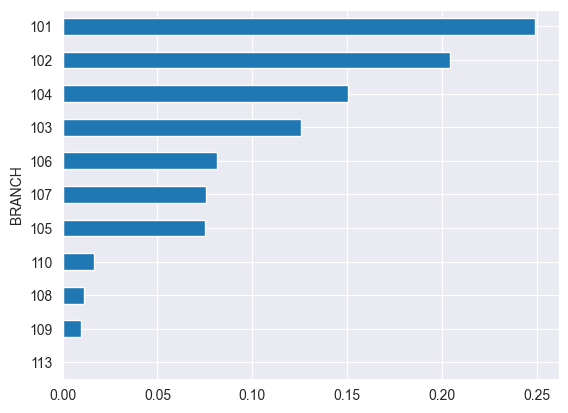

In [17]:
sales_df['BRANCH'].value_counts(normalize=True).sort_values(ascending=True).plot(kind='barh')

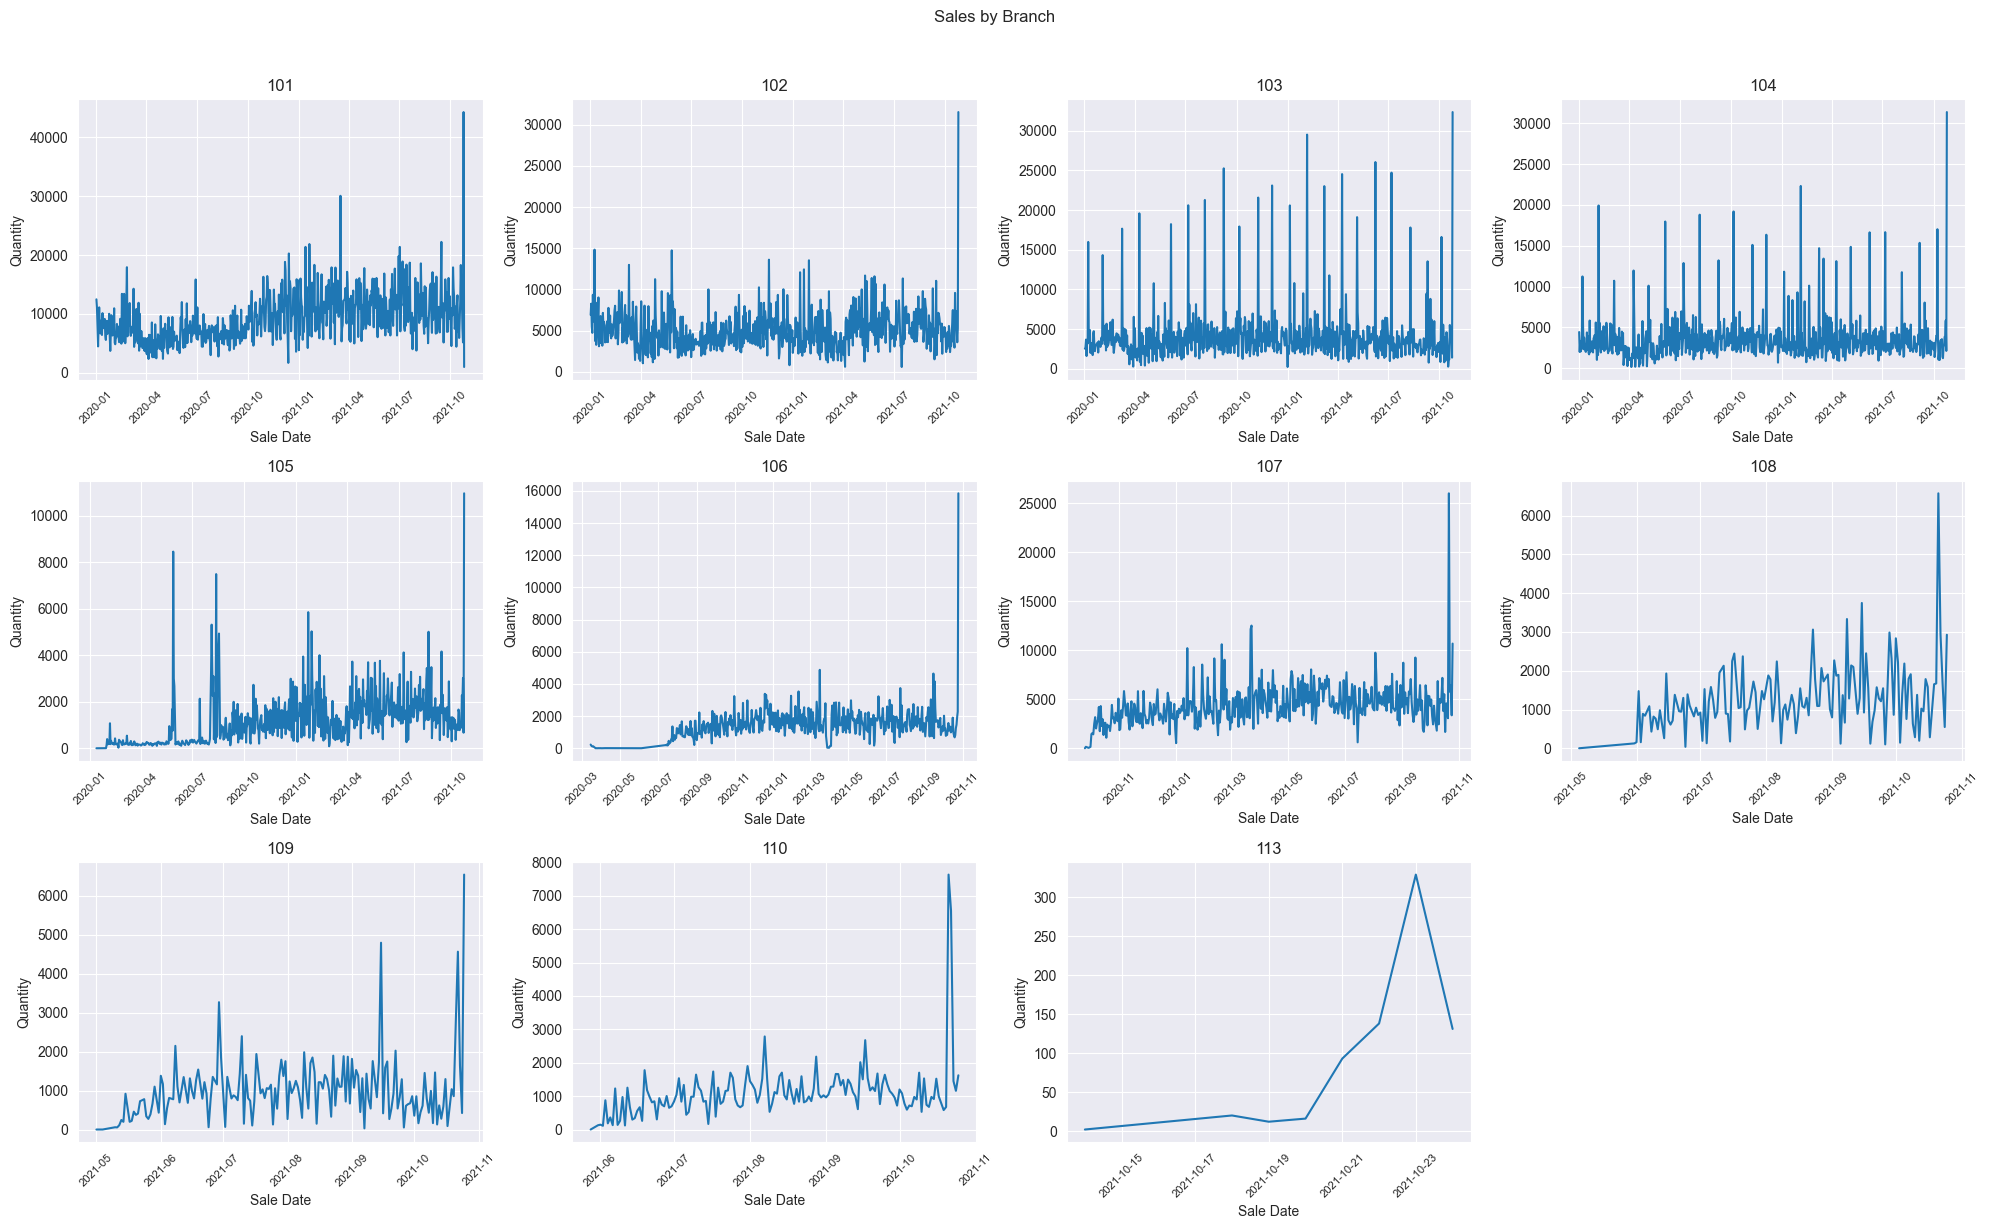

In [18]:
branches = sorted(sales_df["BRANCH"].dropna().astype(str).unique())
n_branches = len(branches)
n_cols = 4
n_rows = max(1, int(np.ceil(n_branches / n_cols)))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows), squeeze=False)
axes = axes.flatten()

for ax, branch in zip(axes, branches):
    sales_df_plot = (
        sales_df.loc[sales_df["BRANCH"].astype(str) == branch, ["SALE_DATE", "QUANTITY"]]
        .groupby("SALE_DATE")
        .sum()
        .sort_index()
    )
    sales_df_plot.index = pd.to_datetime(sales_df_plot.index)

    ax.plot(sales_df_plot.index, sales_df_plot["QUANTITY"].values, linewidth=1.5)
    ax.set_title(branch)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.set_xlabel("Sale Date")
    ax.set_ylabel("Quantity")

for ax in axes[n_branches:]:
    ax.axis("off")

fig.suptitle("Sales by Branch", y=1.02)
fig.tight_layout()
fig.savefig(output_dir / "sales_by_branch.png", dpi=300, bbox_inches="tight")
plt.show()

In [19]:
daily_total = total_sales[['QUANTITY']].asfreq('D')
daily_total.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 664 entries, 2020-01-02 to 2021-10-26
Freq: D
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   QUANTITY  663 non-null    float64
dtypes: float64(1)
memory usage: 10.4 KB


In [20]:
daily_total[daily_total.QUANTITY.isna()]

,QUANTITY
SALE_DATE,
2020-02-25,NaN


- It seems that PharmaSaude didnt had any sales in 28 days in this sample data.

## Sales to Adults

In [21]:
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.graphics.tsaplots import plot_acf
from scipy.signal import periodogram
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.deterministic import CalendarFourier, DeterministicProcess
import datetime as dt
from prophet import Prophet
import statsmodels.api as sm
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.multioutput import MultiOutputRegressor

/Users/isisrosa/Documents/PharmaSaude/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [22]:
prod_sale = sales_df.merge(products_df, on = 'PRODUCT_ID', how = 'left')
prod_sale

,SALE_ID,SALE_DATE,CUSTOMER_ID,PRODUCT_ID,QUANTITY,SALE_CATEGORY,BRANCH,UNIT,LEVEL_1,LEVEL_2,LEVEL_3,LEVEL_4
0,0,2021/02/10,45659.0,17631,1.0,E-COMMERCE,101,NaN,NaN,NaN,NaN,NaN
1,0,2021/02/10,45659.0,34575,1.0,E-COMMERCE,101,UN,ADULT,NUTRITION AND DIETETICS,BARS AND NUTRITIOUS SNACKS,DIETARY COOKIES AND SNACKS
2,1,2021/02/12,70766.0,2240,1.0,E-COMMERCE,101,NaN,NaN,NaN,NaN,NaN
3,2,2021/02/12,42579.0,17707,1.0,E-COMMERCE,101,UN,ADULT,PHARMACY,VITAMINS AND SUPPLEMENTS,VITAMINS AND SUPPLEMENTS
4,2,2021/02/12,42579.0,17707,1.0,E-COMMERCE,101,UN,ADULT,PHARMACY,VITAMINS AND SUPPLEMENTS,VITAMINS AND SUPPLEMENTS
...,...,...,...,...,...,...,...,...,...,...,...,...
3924145,854530,2021/10/23,NaN,36642,10.0,Loja,113,UN,CHILDREN,NUTRITION AND DIETETICS,FOOD SUPPLEMENTS,MOIST AND PASTY FOODS
3924146,854530,2021/10/23,NaN,7332,10.0,Loja,113,UN,CHILDREN,NUTRITION AND DIETETICS,FOOD SUPPLEMENTS,MOIST AND PASTY FOODS
3924147,854530,2021/10/23,NaN,7333,10.0,Loja,113,NaN,NaN,NaN,NaN,NaN
3924148,854531,2021/10/23,106865.0,7528,1.0,Loja,113,UN,ADULT,NUTRITION AND DIETETICS,BARS AND NUTRITIOUS SNACKS,TOOTHPICKS AND ORAL ACCESSORIES


In [23]:
adult_sale= prod_sale[prod_sale['LEVEL_1']== 'ADULT']
adult_sale

,SALE_ID,SALE_DATE,CUSTOMER_ID,PRODUCT_ID,QUANTITY,SALE_CATEGORY,BRANCH,UNIT,LEVEL_1,LEVEL_2,LEVEL_3,LEVEL_4
1,0,2021/02/10,45659.0,34575,1.0,E-COMMERCE,101,UN,ADULT,NUTRITION AND DIETETICS,BARS AND NUTRITIOUS SNACKS,DIETARY COOKIES AND SNACKS
3,2,2021/02/12,42579.0,17707,1.0,E-COMMERCE,101,UN,ADULT,PHARMACY,VITAMINS AND SUPPLEMENTS,VITAMINS AND SUPPLEMENTS
4,2,2021/02/12,42579.0,17707,1.0,E-COMMERCE,101,UN,ADULT,PHARMACY,VITAMINS AND SUPPLEMENTS,VITAMINS AND SUPPLEMENTS
5,2,2021/02/12,42579.0,17707,1.0,E-COMMERCE,101,UN,ADULT,PHARMACY,VITAMINS AND SUPPLEMENTS,VITAMINS AND SUPPLEMENTS
6,2,2021/02/12,42579.0,17707,1.0,E-COMMERCE,101,UN,ADULT,PHARMACY,VITAMINS AND SUPPLEMENTS,VITAMINS AND SUPPLEMENTS
...,...,...,...,...,...,...,...,...,...,...,...,...
3924138,854528,2021/10/24,106864.0,31589,1.0,Loja,113,UN,ADULT,PERFUMERY AND COSMETICS,HYGIENE AND CLEANING,COLLECTORS AND CONTAINERS
3924139,854528,2021/10/24,106864.0,31589,1.0,Loja,113,UN,ADULT,PERFUMERY AND COSMETICS,HYGIENE AND CLEANING,COLLECTORS AND CONTAINERS
3924140,854528,2021/10/24,106864.0,31589,1.0,Loja,113,UN,ADULT,PERFUMERY AND COSMETICS,HYGIENE AND CLEANING,COLLECTORS AND CONTAINERS
3924141,854528,2021/10/24,106864.0,31589,1.0,Loja,113,UN,ADULT,PERFUMERY AND COSMETICS,HYGIENE AND CLEANING,COLLECTORS AND CONTAINERS


<Axes: ylabel='SALE_CATEGORY'>

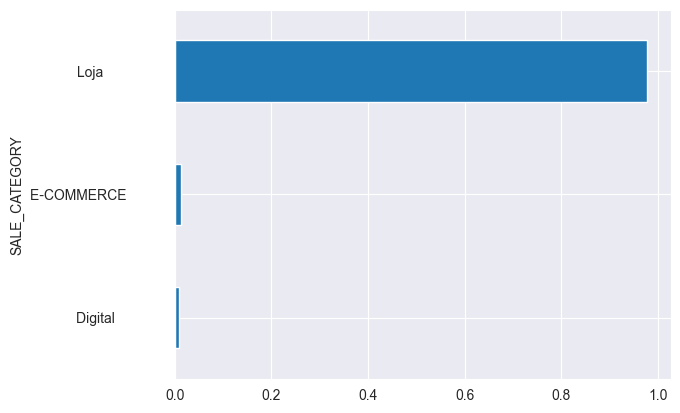

In [24]:
adult_sale['SALE_CATEGORY'].value_counts(normalize=True).sort_values(ascending=True).plot(kind='barh')

<Axes: ylabel='BRANCH'>

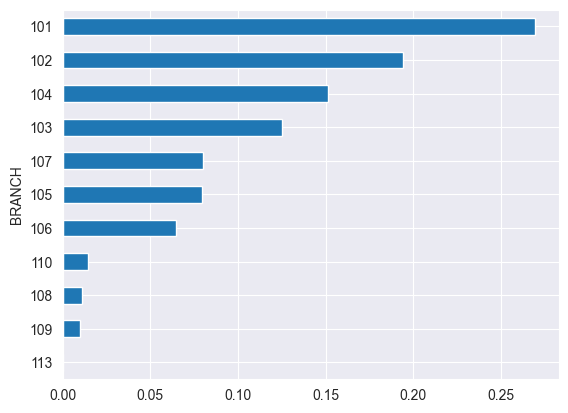

In [25]:
adult_sale['BRANCH'].value_counts(normalize=True).sort_values(ascending=True).plot(kind='barh')

In [26]:
hist_adult= adult_sale[['SALE_DATE','QUANTITY']].groupby('SALE_DATE').sum()

fig=go.Figure()
fig.add_trace(go.Scatter(x=hist_adult.index, y= hist_adult['QUANTITY'], mode='lines', name='Real'))
fig.update_layout(title={'text':'Histogram of Adult Sales','x':0.25})
fig.show()

fig.write_image(output_dir / "hist_adult_sales.png")
#

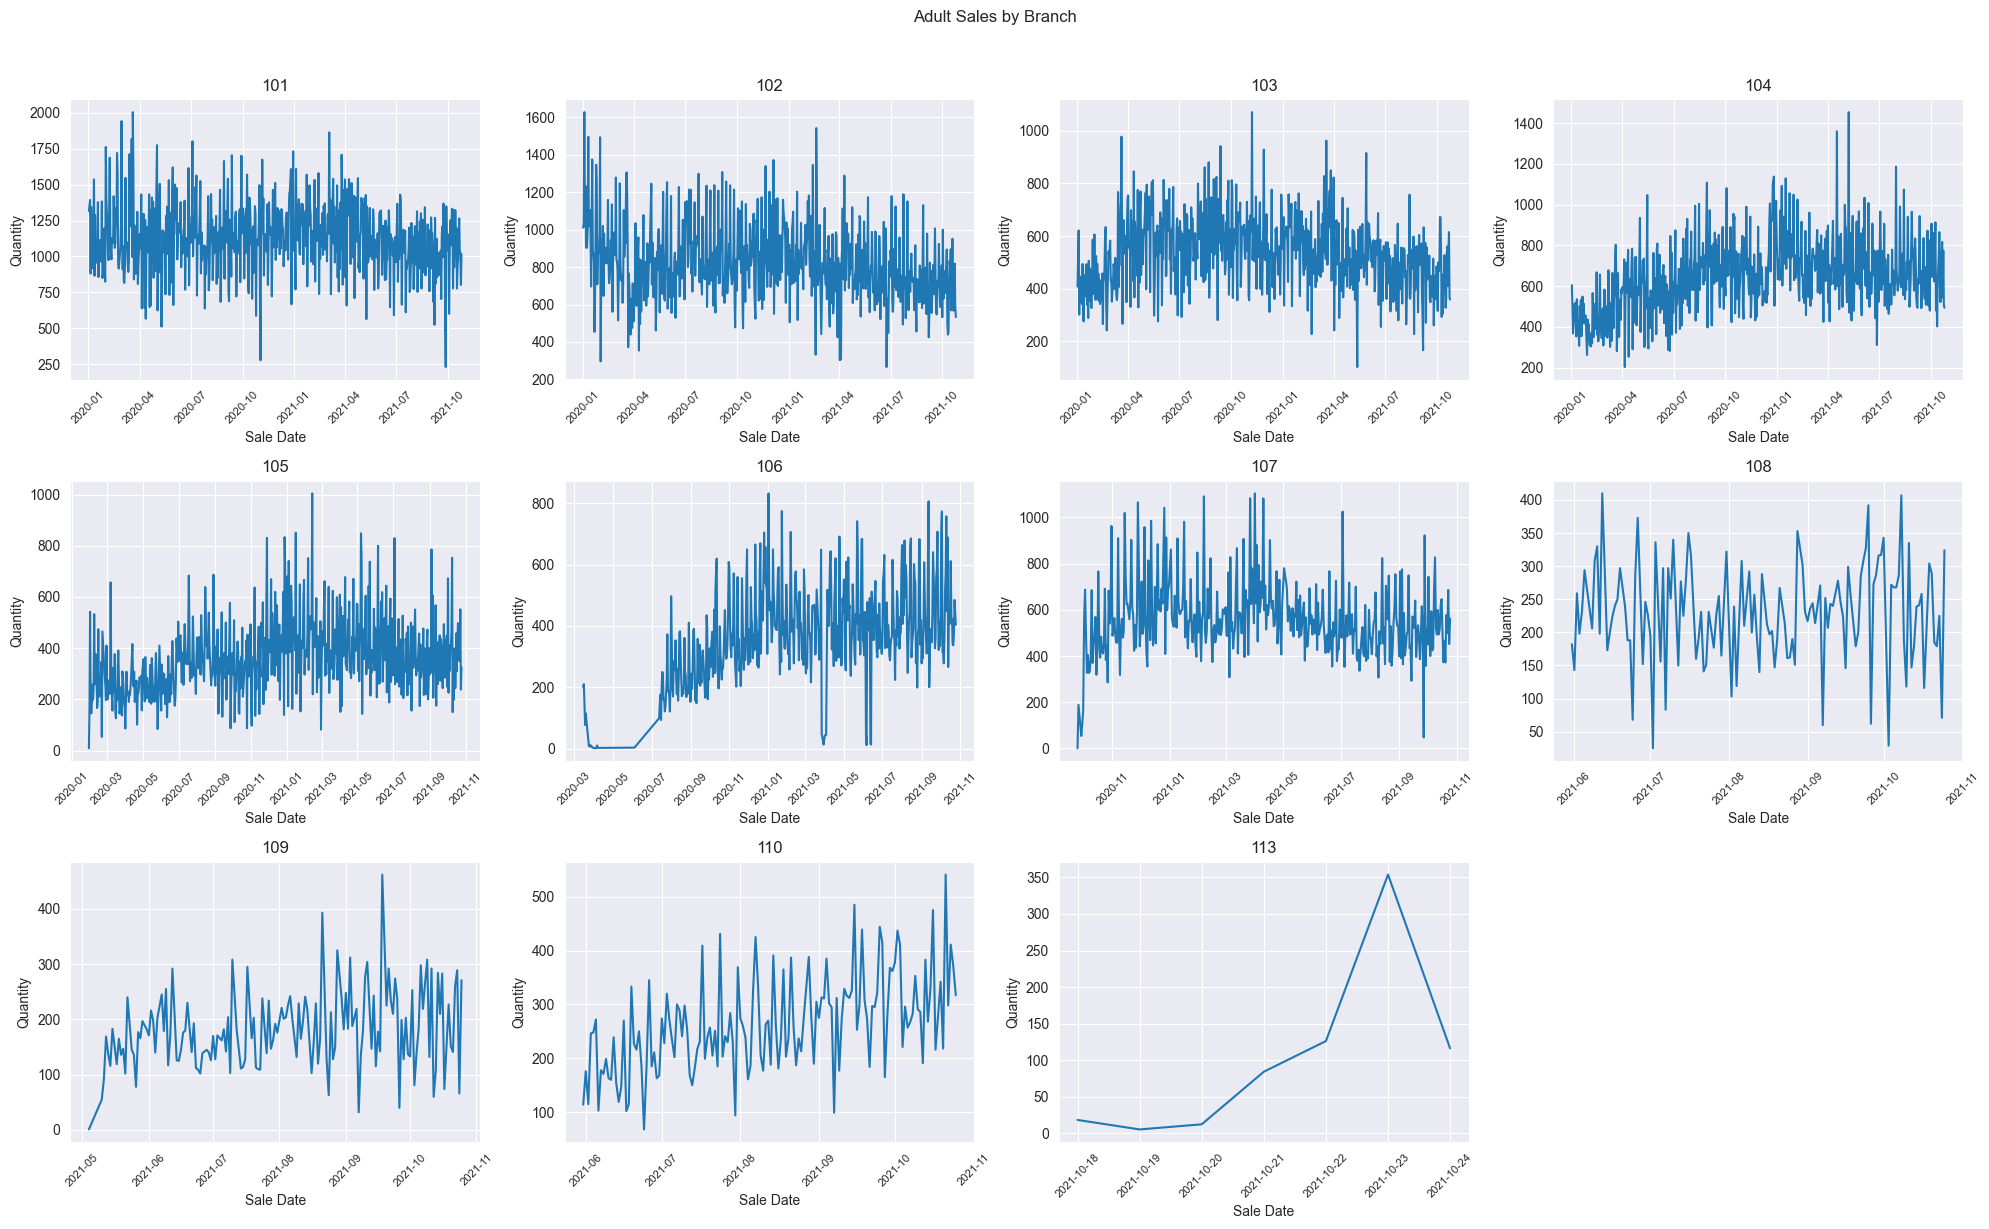

In [27]:
branches = sorted(adult_sale["BRANCH"].dropna().astype(str).unique())
n_branches = len(branches)
n_cols = 4
n_rows = max(1, int(np.ceil(n_branches / n_cols)))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows), squeeze=False)
axes = axes.flatten()

for ax, branch in zip(axes, branches):
    sales_df_plot = (
        adult_sale.loc[adult_sale["BRANCH"].astype(str) == branch, ["SALE_DATE", "QUANTITY"]]
        .groupby("SALE_DATE")
        .sum()
        .sort_index()
    )
    sales_df_plot.index = pd.to_datetime(sales_df_plot.index)

    ax.plot(sales_df_plot.index, sales_df_plot["QUANTITY"].values, linewidth=1.5)
    ax.set_title(branch)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.set_xlabel("Sale Date")
    ax.set_ylabel("Quantity")

for ax in axes[n_branches:]:
    ax.axis("off")

fig.suptitle("Adult Sales by Branch", y=1.02)
fig.tight_layout()
fig.savefig(output_dir / "adult_sales_by_branch.png", dpi=300, bbox_inches="tight")
plt.show()

## Sazonal Cycle Analysis
Para a análise dos ciclos sazonais diversos estratégias podem ser utilizadas. Aqui são realizadas:

- Autocorrelograma parcial
- Periodograma - decomposição em séries de Fourier e análise de cada um dos coeficientes
- Decomposição de série temporal

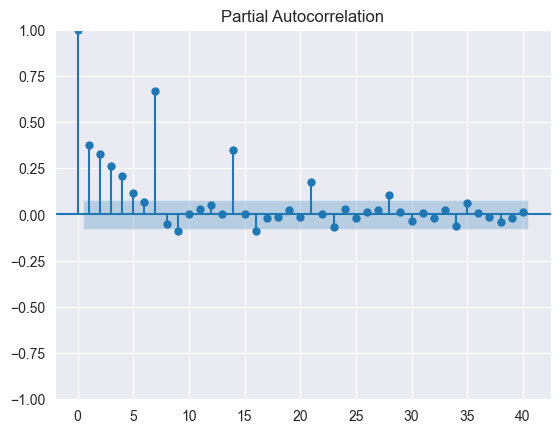

In [28]:
plot_pacf(hist_adult, lags = 40)
plt.show()

**Partial Autocorrelation (PACF):** Measures the correlation of a series with itself at different lags, removing the effect of intermediate lags.

- Lag 0 → always 1.0, as the series is perfectly correlated with itself

- Lags 1 to 4 → positive and significant correlations (~0.35, 0.25, 0.20, 0.10) — indicating that recent values directly influence the current value.

- Lag 7/8 → peak at ~0.68, highly relevant — suggesting a weekly pattern in your data

- Lag 14/15 → another smaller peak (~0.35) — reinforcing the weekly pattern (2 weeks)
Other lags → within the blue band (95% confidence interval) = statistically non-significant

In [29]:
from src.features import plot_periodogram

<Axes: title={'center': 'Periodogram'}, ylabel='Variance'>

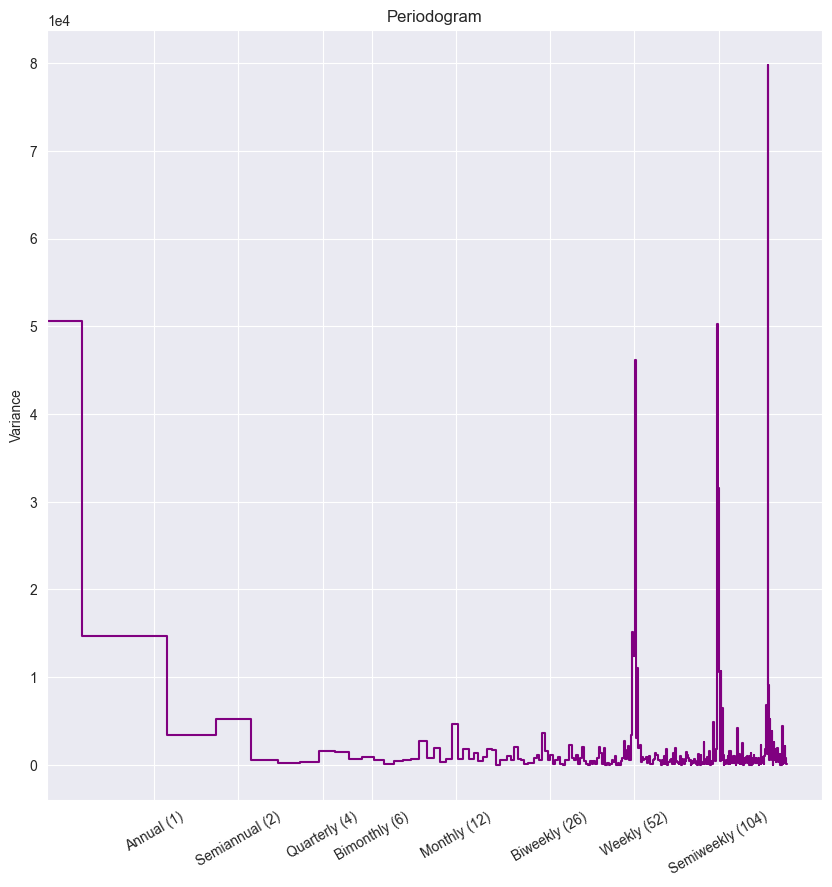

In [30]:
plot_periodogram(hist_adult.QUANTITY)

**Periodogram:** shows how much "energy" (variance) each frequency contributes to the time series. It is like decomposing the series into waves and seeing which ones have the most strength. We can see a strong annual recurrence, bi-weekly (lag 14 of the PACF), weekly (lag 7 of the PACF), and the strongest recurrence is semi-weekly (every 3 or 4 days).

In [31]:
hist_adult.index = pd.to_datetime(hist_adult.index)
hist_adult= hist_adult[['QUANTITY']].asfreq('D')
hist_adult.fillna(0, inplace=True)

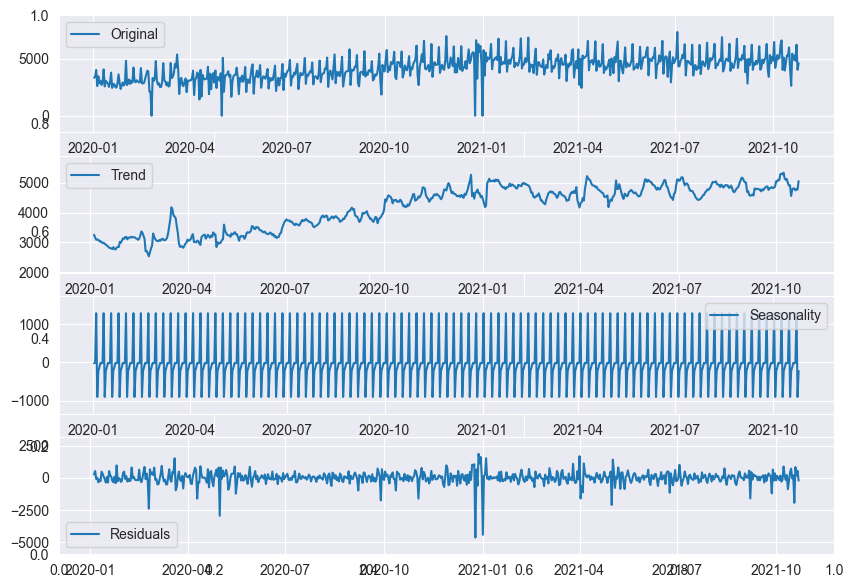

In [32]:
hist_adult.fillna(0, inplace = True)
decomposition = seasonal_decompose(hist_adult.QUANTITY)
# define os componentes
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

# plots
plt.subplots(figsize=(10, 7))
plt.subplot(411)
plt.plot(hist_adult.QUANTITY, label='Original')
plt.legend(loc='best')
plt.margins(y=0.2)

plt.subplot(412)
plt.plot(trend, label='Trend')
plt.legend(loc='best')
plt.margins(y=0.2)

plt.subplot(413)
plt.plot(seasonal, label='Seasonality')
plt.legend(loc='best')
plt.margins(y=0.2)

plt.subplot(414)
plt.plot(residual, label='Residuals')
plt.legend(loc='best')
plt.margins(y=0.2)

fig.tight_layout()
fig.savefig(output_dir / "seasonal_decomposition_adults.png", dpi=300, bbox_inches="tight")
plt.show()

## Feature Engineering

you can find the functions in scr.features

In [33]:
from src.features import add_calendar_features

hist_adult_temp = add_calendar_features(hist_adult)

/var/folders/57/l1rpvp6j6y713553329818440000gn/T/ipykernel_12307/3464477459.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels[col])


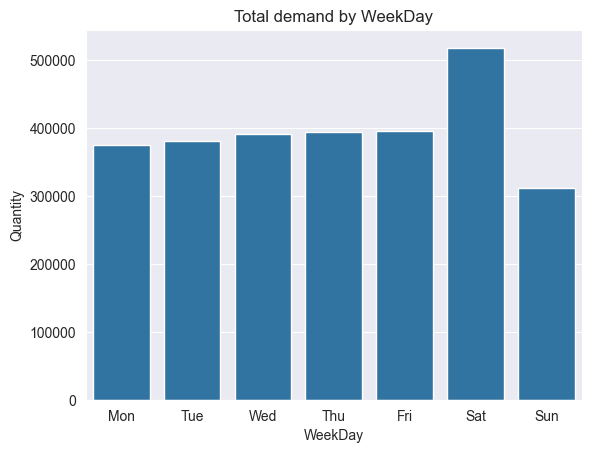

/var/folders/57/l1rpvp6j6y713553329818440000gn/T/ipykernel_12307/3464477459.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels[col])


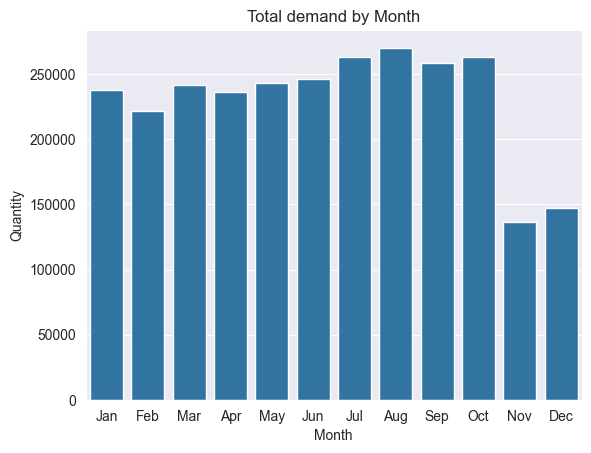

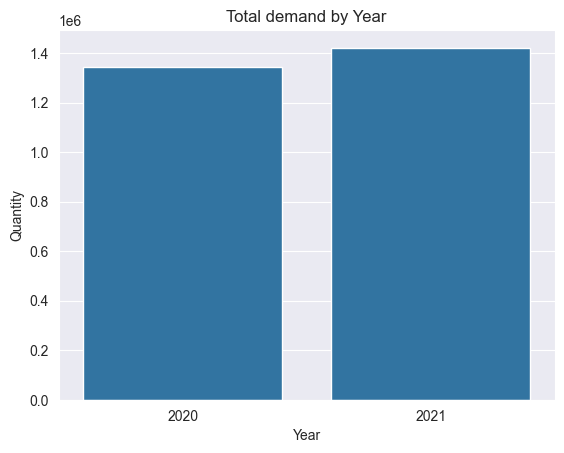

In [34]:
labels = {
    "WeekDay": ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
    "Month":   ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"],
    "Year":    None  # mantém os valores numéricos
}

for col in ["WeekDay", "Month", "Year"]:
    sales_df = hist_adult_temp[[col, 'QUANTITY']].groupby(col).sum()
    ax = sns.barplot(x=sales_df.index, y=sales_df['QUANTITY'].values)
    if labels[col]:
        ax.set_xticklabels(labels[col])
    ax.set_title(f'Total demand by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Quantity')
    fig.tight_layout()
    fig.savefig(output_dir / f"demand_{col}_adults.png", dpi=300, bbox_inches="tight")
    plt.show()




The analysis based on temporal features allows identifying:

* A weekly seasonality, already confirmed by the correlogram (PACF), with a clear higher number of sales on Saturdays (as these are physical stores, this is justified, since it is a day when a large portion of customers likely have the free time to shop in-store) and a lower number of sales on Sundays (where it can be assumed that stores close earlier than on regular days)
* Although the month-over-month analysis chart seems to indicate a lower volume of sales in the last months of the year, attention must be paid to the fact that the months of November and December 2021 are not present in the historical database, which would justify the observed behavior.

In [35]:
from src.features import add_lag_features


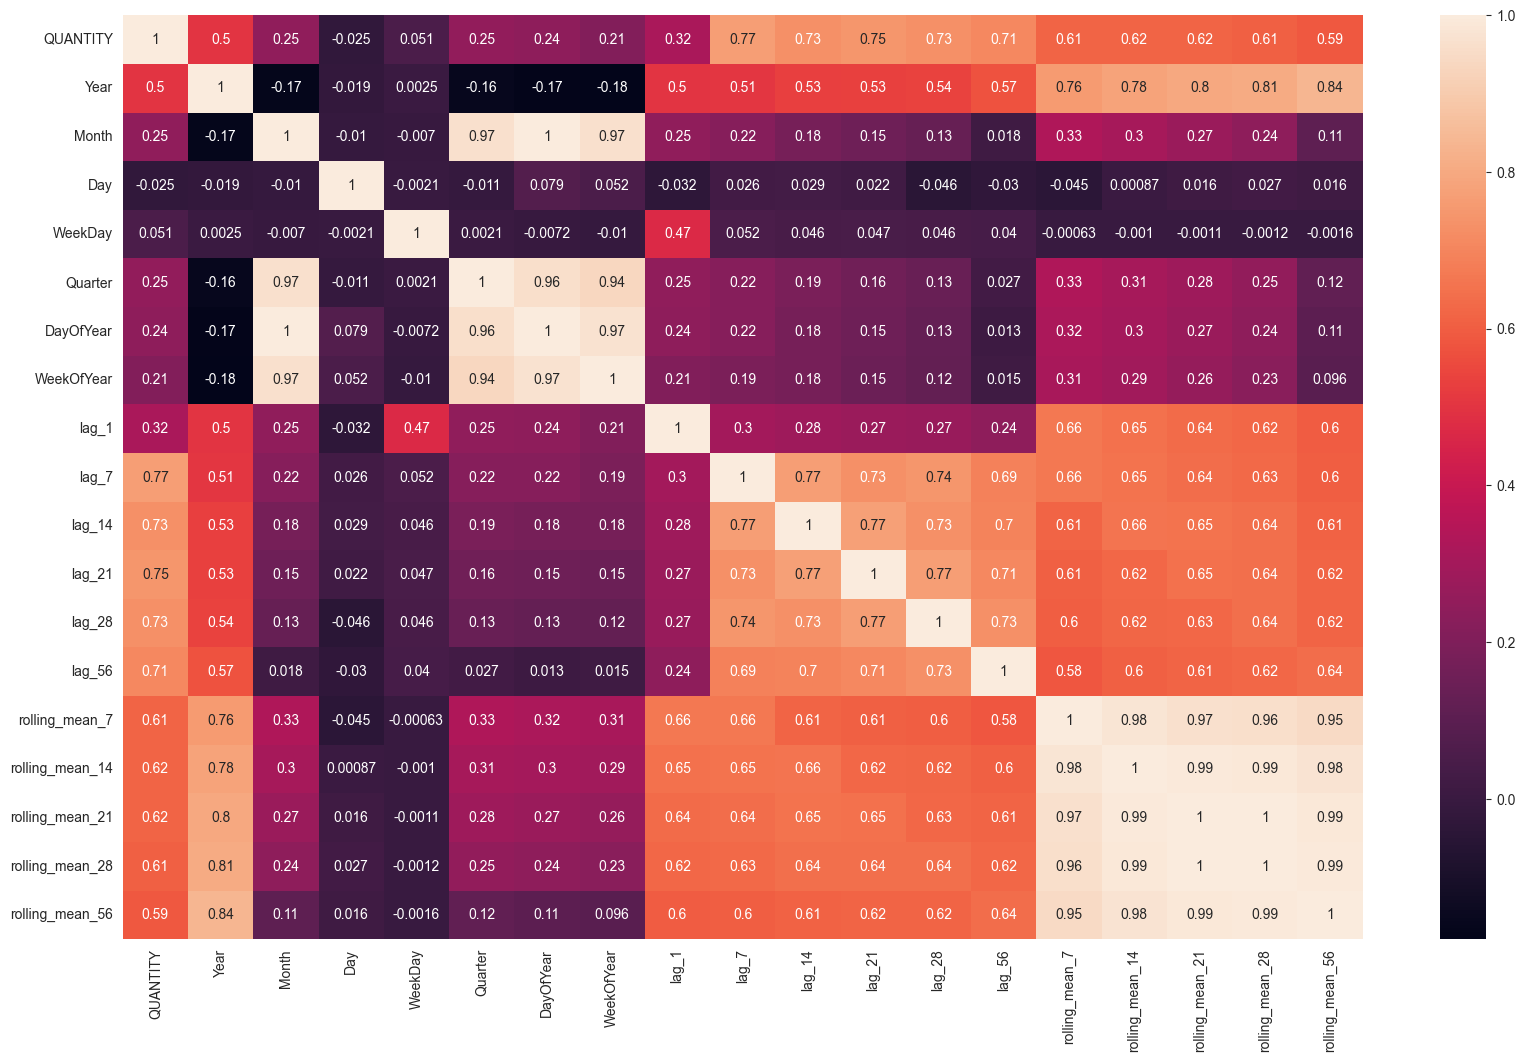

In [36]:
#Correlation Heatmap

df_featured = add_lag_features(add_calendar_features(hist_adult))

plt.figure(figsize=(20,12))
corr = df_featured.corr()
sns.heatmap(corr, annot=True)
fig.tight_layout()
fig.savefig(output_dir / f"lag_features_heatmap_adults.png", dpi=300, bbox_inches="tight")
plt.show()

We can see a high correlation between lags 7, 14, 21, and 28. This means that the demand from the previous week explains the current week's demand very well.
The strong correlation with Lag 56 also denotes a strong bi-monthly pattern in sales.
The rolling mean also explains the demand well, especially the rolling mean of the last 7 days (rolling_mean_7), which is a good short-term predictor.

---

# Modeling

For modeling, I will use two models: SARIMAX and Prophet. These were chosen due to the seasonal pattern of the data. I split the dataset into training and testing sets while respecting the time variable. Thus, the last 180 days (6 months in daily frequency) were used as the training set.

Remarks:

The way the split was performed allocates very little data for training, which could compromise model performance and lead to overfitting on the available data. Furthermore, a validation set was not separated in this split, and the metrics were obtained directly using the test set. While this approach is not ideal, it is necessary due to the limited amount of data and the large time horizon of the forecast.

In [47]:
train_end = hist_adult.index.max() - pd.Timedelta(days=180)



In [48]:
train_df = hist_adult.loc[:train_end]
test_df = hist_adult.loc[train_end + pd.Timedelta(days=1):]

In [49]:
# division size:
print("Size of train set: ", train_df.shape)
print("Size of test set: ", test_df.shape)
# test set
train_df.head()

Size of train set:  (483, 1)
Size of test set:  (180, 1)


,QUANTITY
SALE_DATE,
2020-01-02,3340.0
2020-01-03,3420.0
2020-01-04,4010.0
2020-01-05,2605.0
2020-01-06,3461.0


In [50]:
from src.evaluate import compute_error

In [51]:
metrics = {}

## Sarimax

In [53]:
df_m = train_df.copy()
df_mt = test_df.copy()

In [56]:
from src.train import FourierFeaturizer

fourier_feat = FourierFeaturizer(m=96, k=5)
_, exog_train_sarimax = fourier_feat.fit_transform(df_m)
exog_train_sarimax.index = df_m.index

In [ ]:
from src.train import FourierFeaturizer

y_train = df_m.iloc[:, 0] if isinstance(df_m, pd.DataFrame) else df_m

fourier_feat = FourierFeaturizer(m=96, k=5)
_, exog_train_sarimax = fourier_feat.fit_transform(y_train)
exog_train_sarimax.index = y_train.index

model = sm.tsa.statespace.SARIMAX(
    endog=y_train,
    order=(0, 1, 2),
    exog=exog_train_sarimax,
    freq='D',
)
res = model.fit(disp=False)

ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject

In [ ]:
model = sm.tsa.statespace.SARIMAX(endog = df_m,
                                  order=(0,1,2),
                                  exog = exog_train_sarimax,
                                  freq='D')
res = model.fit()

In [ ]:
exog_test_sarimax = fourier_feat.transform(X = df_mt, n_periods=df_mt.shape[0])[1]
exog_test_sarimax.index = df_mt.index

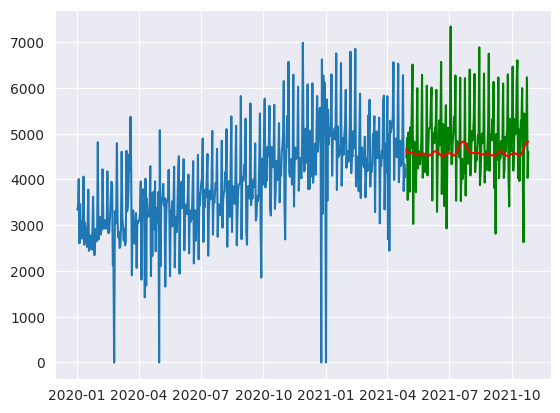

In [ ]:
# Gerando as previsões
y_predict = res.predict(start=df_mt.index.min(), end=df_mt.index.max(), exog=exog_test_sarimax)
#plot dos resultados
plt.plot(df_m.QUANTIDADE)
plt.plot(df_mt.QUANTIDADE, color='green')
plt.plot(y_predict,color= 'red')

In [ ]:
# The line below created a self-referential series, causing a recursion error.
# y_predict['pred'] = y_predict
# y_predict is already a pandas Series with the predictions.

In [ ]:
calculo_erro(y_predict, df_mt.QUANTIDADE)

       MÉTRICAS DE ERRO       
  MAPE: 13.17%
  MAE:  638.10


{'MAPE': 0.13171815170828166, 'MAE': np.float64(638.1029305062046)}

In [ ]:
# ajuste do dataset de treino e teste
train_prophet = df_train[['QUANTIDADE']].reset_index()
train_prophet.columns = ['ds', 'y']
test_prophet = df_test[['QUANTIDADE']].reset_index()
test_prophet.columns = ['ds', 'y']
train_prophet.head()

,ds,y
0,2020-01-02,3340.0
1,2020-01-03,3420.0
2,2020-01-04,4010.0
3,2020-01-05,2605.0
4,2020-01-06,3461.0


In [ ]:
# instancia prophet e treina
m = Prophet(yearly_seasonality = True)
m.add_country_holidays(country_name='BR')
m.fit(train_prophet)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


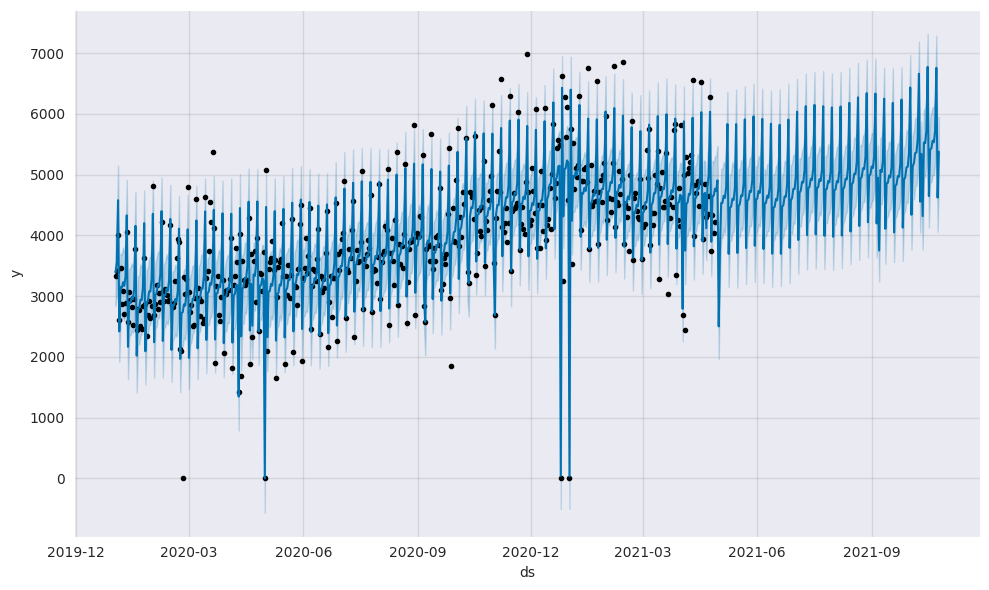

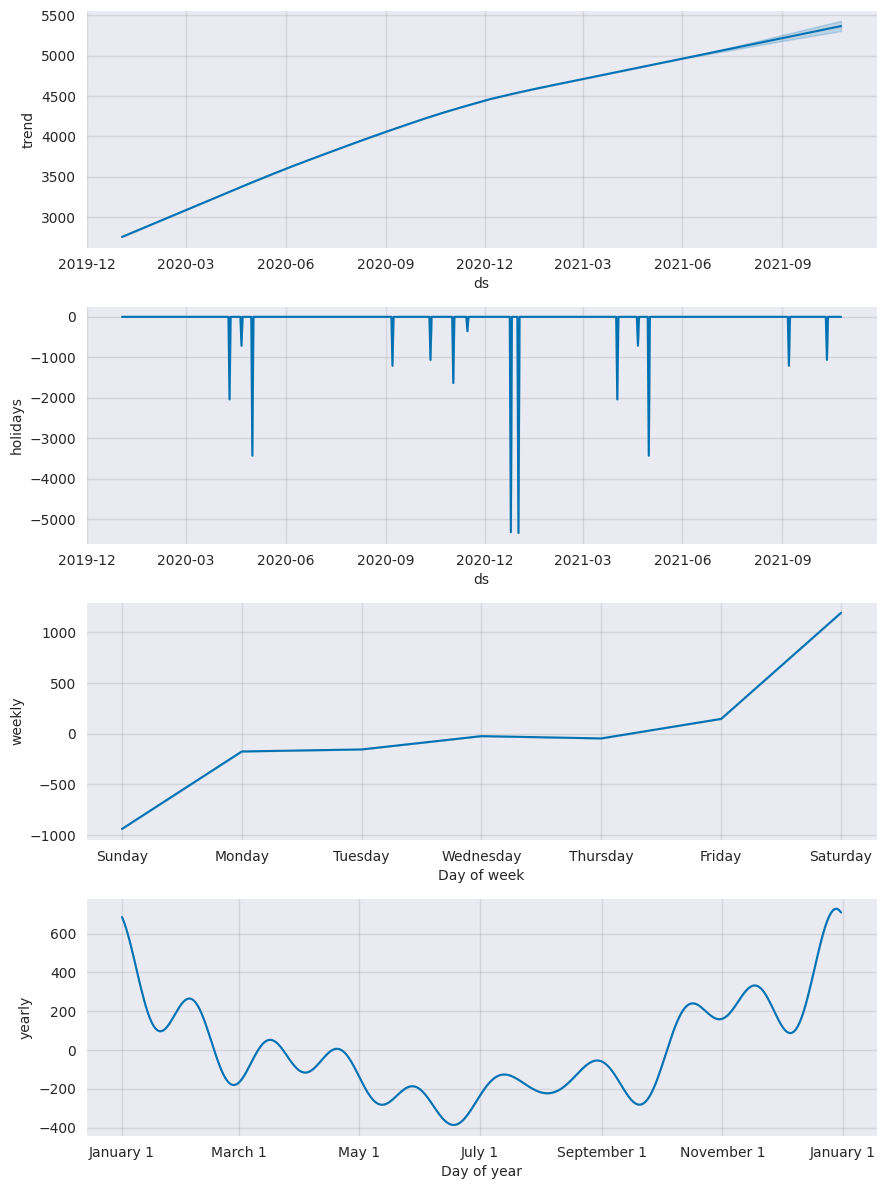

In [ ]:
# construção do dataset de teste para alimentar o modelo
future = m.make_future_dataframe(periods=len(df_test))

# realiza previsão
forecast = m.predict(future)

#plota previsão
m.plot(forecast);

#plota componentes
m.plot_components(forecast);

In [ ]:
prophet_ds = forecast.set_index('ds')[['yhat', 'yhat_lower', 'yhat_upper']].join(test_prophet.set_index('ds'))

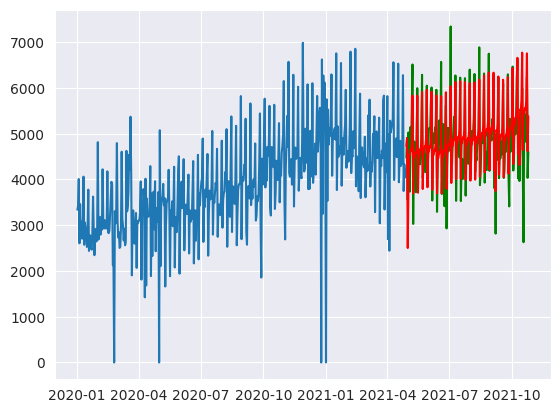

In [ ]:
# plot dos resultados
plt.plot(df_train.QUANTIDADE)
plt.plot(df_test.QUANTIDADE, color='green')
plt.plot(prophet_ds['yhat'].tail(180), color='red')

In [ ]:
prophet_pred_real = prophet_ds[~prophet_ds.y.isna()]

In [ ]:
calculo_erro(prophet_pred_real.yhat, prophet_pred_real.y)

       MÉTRICAS DE ERRO       
  MAPE: 8.33%
  MAE:  365.84


{'MAPE': 0.08327104908565329, 'MAE': np.float64(365.84410740823085)}

## Resultado

O modelo que melhor performou foi o Prophet: MAPE: 8.33% e MAE: 365,84

---

# Deploy
Agora, vamos utilizar o modelo para ser utilizado durante a produção (dia a dia)


In [ ]:
import pickle
from prophet import Prophet
from datetime import datetime

# ── Configurações ──────────────────────────────────────
MODEL_PATH   = "prophet_farmasaude.pkl"
HORIZON_DAYS = 180  # ~6 meses

# ── Retreino ───────────────────────────────────────────
def retreinar_modelo(df):
    """df deve ter colunas 'ds' e 'y' — já no formato do seu notebook"""
    print(f"[{datetime.now():%Y-%m-%d %H:%M:%S}] Iniciando retreino...")
    print(f"  Período: {df['ds'].min().date()} → {df['ds'].max().date()}")

    m = Prophet(yearly_seasonality=True, weekly_seasonality=True,
                daily_seasonality=False, seasonality_mode="additive")
    m.add_country_holidays(country_name="BR")
    m.fit(df)

    with open(MODEL_PATH, "wb") as f:
        pickle.dump(m, f)

    print(f"  Modelo salvo em: {MODEL_PATH}")
    return m

# ── Previsão ───────────────────────────────────────────
def prever(model, horizon_days=HORIZON_DAYS):
    print(f"\n[{datetime.now():%Y-%m-%d %H:%M:%S}] Gerando previsão para {horizon_days} dias...")

    future   = model.make_future_dataframe(periods=horizon_days, freq="D")
    forecast = model.predict(future)

    resultado = (
        forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]]
        .tail(horizon_days)
        .rename(columns={"ds": "Data", "yhat": "Previsao",
                         "yhat_lower": "Limite_Inferior", "yhat_upper": "Limite_Superior"})
        .reset_index(drop=True)
    )

    for col in ["Previsao", "Limite_Inferior", "Limite_Superior"]:
        resultado[col] = resultado[col].clip(lower=0).round(0).astype(int)

    print(f"  Horizonte: {resultado['Data'].min().date()} → {resultado['Data'].max().date()}")
    print(f"  Média diária: {resultado['Previsao'].mean():,.0f} unidades")
    print(f"  Total no período: {resultado['Previsao'].sum():,.0f} unidades")

    return resultado

# ── Execução ───────────────────────────────────────────
# train_prophet já existe no seu notebook com colunas 'ds' e 'y'
model     = retreinar_modelo(train_prophet)
resultado = prever(model)
resultado.head()

[2026-03-08 17:37:40] Iniciando retreino...
  Período: 2020-01-02 → 2021-04-28
  Modelo salvo em: prophet_farmasaude.pkl

[2026-03-08 17:37:41] Gerando previsão para 180 dias...
  Horizonte: 2021-04-29 → 2021-10-25
  Média diária: 4,931 unidades
  Total no período: 887,550 unidades


,Data,Previsao,Limite_Inferior,Limite_Superior
0,2021-04-29,4731,4196,5311
1,2021-04-30,4906,4314,5427
2,2021-05-01,2503,1947,3012
3,2021-05-02,3787,3246,4354
4,2021-05-03,4533,3975,5126
